# Figure 2: Performance Summary

Translation of `Figure02_performanceSummary.m`

## What this notebook does

Shows three performance measures for the online (OL) task:

- **Panel A: Example session trajectories**: step sequences from one participant from cohort 1, block 2 (coin penalty) at the lowest signal-to-noise ratio (SNR). Choice side is shown via marker shape/fill rather than color: a filled right-pointing triangle marks a right choice, an open left-pointing triangle marks a left choice.

- **Panel B: Congruence per non-decision time (NDT) lag**: for each participant, the fraction of trials where the sign of the pigeon position at NDT lag matches the choice direction. The lag with highest congruence is the estimated NDT.

- **Panel C: Accuracy vs. median decision time (DT)**: one point per participant with error bars spanning the 25th–75th percentile — the interquartile range of the raw per-trial DT distribution for the x-errorbar, and a Clopper–Pearson 50% CI (25th–75th percentile of the binomial posterior) for the y-errorbar — plus an ideal-observer speed-accuracy benchmark curve (red, the color of optimal benchmarks throughout) and black diamonds on the axes at the group medians. Shows individual variability in both accuracy and DT and that, as expected, participants who wait longer (higher DT) are more accurate.

**Data**: OL task, block 2 (penalty block), lowest SNR condition.

## Imports

Imports standard scientific Python libraries and `get_data_table` from the pigeon package. No data loading or filtering here.

## Load data

Loads all OL (online) trials via `get_data_table(task_type='OL')`. This applies the following processing and filtering internally:
- Reads all CSV files in `DATA_DIR/Pigeon_OL/prolificcsvs/`
- Retains only rows with a valid `trial_number`
- Computes `bound`, `DT`, `RT` from step sequences via `get_bounds`
- Marks wall-hit trials (`wall_hit=True`) where the pigeon reached the screen edge (|position| ≥ 0.75)
- Marks trials below the per-(block, SNR) RT reliability cutoff (`rt_below_cutoff=True`)
- Applies bias correction from `boundBiasCorrection.mat` if present
- Combines blocks 4–6 into 1–3 (blocked-SNR logic)

No rows are dropped here — all subjects and blocks are retained. Note: unlike the
bound-focused notebooks (e.g. `Figure03_boundSummary`), this notebook does **not** call
`get_good_trial_array` and does **not** exclude `rt_below_cutoff` trials — see the
filter rationale in the next cell.

## Compute per-subject summaries

Computes congruence and performance statistics for each subject.

**Data included**: Trials from block 2 (`BLOCK=2`), lowest SNR condition (`min_snr`),
with `DT > 0`, `trial_number ≥ 10`, and `wall_hit = False`.

This intentionally differs from the project's standard trial-quality filter
(`get_good_trial_array`: `DT ≥ 2`, `rt_below_cutoff` excluded), used by the
bound-focused notebooks (e.g. `Figure03_boundSummary`). That stricter filter exists to
protect the reliability of the per-trial **bound** estimate, which needs at least two
post-NDT steps to locate a midpoint crossing. This notebook never uses the `bound`
column — Panel A plots raw step trajectories and Panel C uses only `DT` and `correct`
— so the bound-reliability constraint doesn't apply here. `DT > 0` simply excludes
trials with no measurable decision time (RT ≡ NDT); `rt_below_cutoff` trials are kept
for the same reason `bound`-reliability filtering is skipped — that cutoff is also
calibrated for bound reliability, not for accuracy/DT. Wall-hit trials are still
excluded because their RT is inflated by the screen edge and their DT is unreliable
regardless of what it's used for.

The `congruence` array is read from the first row of each subject's data (stored during
`get_bounds` in `get_data_table`).

Also computes a Clopper–Pearson 50% CI on accuracy, the interquartile range (25th/75th
percentile) of the raw per-trial DT distribution, and the Spearman correlation between
accuracy and median DT.

In [1]:
import sys
sys.path.insert(0, '..')  # find pigeon package in parent directory

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats

from pigeon.data import get_data_table
from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import CONDITION_LABELS, DATA_COLOR, FONT_RC, OPTIMAL_COLOR, add_panel_label, format_p

In [2]:
# Load all online trials (matches MATLAB: dataTableOL = getPigeon_dataTable('taskType', 'OL'))
data_table_ol = get_data_table(task_type='OL')

In [3]:
# Parameters (match MATLAB defaults)
BLOCK = 2          # which block to use for performance summary
EXAMPLE_SESSION = 10  # subject index for the example trajectory panel

subjects = np.sort(data_table_ol['subject_index'].dropna().unique())
n_subjects = len(subjects)
a_snrs = np.abs(data_table_ol['snr'].to_numpy())
min_snr = np.nanmin(a_snrs)

# Select trials from the target block at the lowest SNR (hardest condition)
lg_good = (
    (data_table_ol['DT'] > 0) &
    (data_table_ol['block_index'] == BLOCK) &
    pd.Series(np.isclose(a_snrs, min_snr), index=data_table_ol.index) &
    (data_table_ol['trial_number'] >= 10) &
    (data_table_ol['wall_hit'] == False)
)

# Number of NDT lags reported by get_bounds/get_data_table (max_ndt, default 5).
# Derived from the data rather than hardcoded so this notebook tracks whichever
# value get_data_table is actually called with.
N_NDT = next(arr.shape[0] for arr in data_table_ol['congruence'] if isinstance(arr, np.ndarray))

congruence_summary = np.full((n_subjects, N_NDT), np.nan)  # congruence at each NDT lag (0 .. N_NDT-1)
performance_summary = np.full((n_subjects, 2), np.nan)  # columns: accuracy, median DT
n_correct_summary  = np.full(n_subjects, np.nan)
n_trials_summary   = np.full(n_subjects, np.nan)
dt_ci_summary      = np.full((n_subjects, 2), np.nan)   # [25th, 75th] percentile (IQR) of DT

rng = np.random.default_rng(0)

for si, subj in enumerate(subjects):
    ls = data_table_ol['subject_index'] == subj

    # Pull congruence array stored on the first row of each subject
    first_idx = ls[ls].index[0]
    cong = data_table_ol.loc[first_idx, 'congruence']
    if cong is not None and isinstance(cong, np.ndarray) and cong.ndim == 2 and cong.shape[0] >= N_NDT and cong.shape[1] >= 1:
        congruence_summary[si] = cong[:N_NDT, 0]  # first SNR level, first N_NDT NDT lags

    # Accuracy and median DT for this subject's good trials
    lsg = lg_good & ls
    if lsg.any():
        subset = data_table_ol[lsg]
        n_correct = int(subset['correct'].sum())
        n_trials  = int(subset['correct'].notna().sum())
        dt_vals   = subset['DT'].dropna().values

        performance_summary[si, 0] = n_correct / n_trials
        performance_summary[si, 1] = np.median(dt_vals)
        n_correct_summary[si] = n_correct
        n_trials_summary[si]  = n_trials

        # IQR (25th/75th percentile) of the raw per-trial DT distribution
        if len(dt_vals) > 1:
            dt_ci_summary[si] = np.percentile(dt_vals, [25, 75])

# Clopper-Pearson 50% CI on accuracy (25th/75th percentile of the beta posterior)
acc_lo = np.full(n_subjects, np.nan)
acc_hi = np.full(n_subjects, np.nan)
for si in range(n_subjects):
    if np.isfinite(n_correct_summary[si]):
        k = int(n_correct_summary[si])
        n = int(n_trials_summary[si])
        acc_lo[si] = scipy.stats.beta.ppf(0.25, k,     n - k + 1)
        acc_hi[si] = scipy.stats.beta.ppf(0.75, k + 1, n - k)

# Max congruence per subject (peak over the N_NDT lags) — a proxy for how
# consistently a subject's choice tracked the pigeon's position, i.e. how much
# they were engaging with the evidence vs. guessing.
max_congruence = np.nanmax(congruence_summary, axis=1)

# Spearman correlation between accuracy and median DT
valid = np.isfinite(performance_summary[:, 0]) & np.isfinite(performance_summary[:, 1])
r_spearman, p_spearman = scipy.stats.spearmanr(performance_summary[valid, 0], performance_summary[valid, 1])
print(f'Accuracy = {np.nanpercentile(performance_summary[:,0],50):.2f} '
      f'[{np.nanpercentile(performance_summary[:,0],25):.2f} {np.nanpercentile(performance_summary[:,0],75):.2f}], '
      f'Median DT = {np.nanpercentile(performance_summary[:,1],50):.2f} '
      f'[{np.nanpercentile(performance_summary[:,1],25):.2f} {np.nanpercentile(performance_summary[:,1],75):.2f}]')
print(f'Spearman acc vs DT = {r_spearman:.2f}, {format_p(p_spearman)}')

r_cong_acc, p_cong_acc = scipy.stats.spearmanr(max_congruence[valid], performance_summary[valid, 0])
r_cong_dt,  p_cong_dt  = scipy.stats.spearmanr(max_congruence[valid], performance_summary[valid, 1])
print(f'Max congruence range = [{np.nanmin(max_congruence):.2f}, {np.nanmax(max_congruence):.2f}]')
print(f'Spearman max congruence vs accuracy = {r_cong_acc:.2f}, {format_p(p_cong_acc)}')
print(f'Spearman max congruence vs median DT = {r_cong_dt:.2f}, {format_p(p_cong_dt)}')

Accuracy = 0.76 [0.68 0.81], Median DT = 5.00 [3.00 7.25]
Spearman acc vs DT = 0.67, p<0.001
Max congruence range = [0.50, 0.99]
Spearman max congruence vs accuracy = 0.50, p<0.001
Spearman max congruence vs median DT = 0.55, p<0.001


## Ideal-observer benchmark for panel 3

To interpret where a subject's (median DT, accuracy) point sits, we compare it to a
simple ideal bound-crossing observer: no NDT, no lapses, no bound variability, no wall —
just a random walk with the task's actual per-step generative statistics, run to
threshold crossing at a fixed bound. Sweeping the bound gives a full speed-accuracy
frontier (DT, accuracy) curve, i.e. the best any fixed-bound strategy could do at this
SNR. Real subjects should generally fall on or below this curve; simulating with no NDT
matches how `DT` itself is already defined here (RT with the per-subject NDT already
subtracted out via `get_bounds`).

**Generative parameters**: `generative_mean=0.05`, `generative_std=0.15` for the
`min_snr` (=0.05/0.15=0.333) condition used throughout this notebook. These are the
values already documented in `Make_biasCorrection.ipynb` for this SNR bin, and they
match this notebook's own data closely: the empirical per-step increment SD, measured
directly from the raw `steps` sequences for these exact filtered trials, is ≈0.152.</cell id="cell-6">


In [4]:
def simulate_ideal_observer(bounds, generative_mean=0.05, generative_std=0.15,
                             n_sim=50000, max_steps=1000, rng=None):
    """Simulate a no-NDT, no-wall bound-crossing ideal observer.

    For each candidate bound, runs n_sim independent random walks with per-step
    increments ~ N(generative_mean, generative_std), starting at 0, until
    |position| first exceeds the bound. Returns the mean crossing step (DT) and
    the fraction of crossings on the correct (positive-drift) side (accuracy).
    """
    if rng is None:
        rng = np.random.default_rng(0)
    mean_dt  = np.full(len(bounds), np.nan)
    accuracy = np.full(len(bounds), np.nan)
    for bi, b in enumerate(bounds):
        position = np.zeros(n_sim)
        active   = np.ones(n_sim, dtype=bool)
        dt       = np.full(n_sim, np.nan)
        correct  = np.full(n_sim, np.nan)
        for step in range(1, max_steps + 1):
            n_active = int(active.sum())
            if n_active == 0:
                break
            position[active] += rng.normal(generative_mean, generative_std, size=n_active)
            crossed = active & (np.abs(position) >= b)
            if crossed.any():
                dt[crossed]      = step
                correct[crossed] = position[crossed] > 0
                active &= ~crossed
        mean_dt[bi]  = np.nanmean(dt)
        accuracy[bi] = np.nanmean(correct)
    return mean_dt, accuracy


ideal_bounds = np.arange(0.02, 0.73, 0.01)
ideal_dt, ideal_acc = simulate_ideal_observer(ideal_bounds, rng=np.random.default_rng(0))
print(f'Ideal observer: bound {ideal_bounds[0]:.2f}-{ideal_bounds[-1]:.2f} -> '
      f'DT {ideal_dt[0]:.1f}-{ideal_dt[-1]:.1f}, accuracy {ideal_acc[0]:.2f}-{ideal_acc[-1]:.2f}')

Ideal observer: bound 0.02-0.72 -> DT 1.1-15.5, accuracy 0.64-0.97


## Figure

Publication layout matching MATLAB's `getPLOT_axes` call:

```matlab
getPLOT_axes(2, 8.5, [4,4,4], {1,1,1}, 2.0, 1.0, [], 'Pigeons', true)
```

- **Width**: 8.5 cm (1 JNeurosci column)
- **Row heights**: 4 cm each; vertical panel separation 2.0 cm
- **Font size**: 12 pt axis and tick labels, 8 pt in-panel text (legend, colorbar)
- Saves to `Figure02.pdf`.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


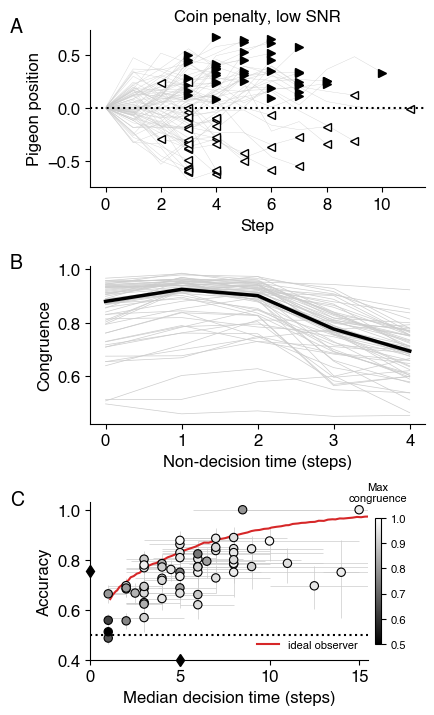

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure02.pdf (+ .png)


In [5]:
from matplotlib.ticker import MaxNLocator
import matplotlib.gridspec as gridspec

CM  = 1 / 2.54
WID = 8.5
HTS = [4.0, 4.0, 4.0]
PSH = 2.0
FS  = 12

fig_h       = sum(HTS) + PSH * (len(HTS) - 1)   # 16 cm
hspace_frac = PSH / np.mean(HTS)

# Set fonts before creating axes: axes take their tick sizes at creation, so updating rcParams
# afterwards left the main panels' tick labels at the 10-pt default.
plt.rcParams.update({'font.size': FS, 'axes.labelsize': FS, 'axes.titlesize': FS, **FONT_RC})
fig = plt.figure(figsize=(WID * CM, fig_h * CM))
gs = gridspec.GridSpec(3, 1, figure=fig,
                       hspace=hspace_frac,
                       left=0, right=1, bottom=0, top=1)
axs = [fig.add_subplot(gs[r]) for r in range(3)]
FS_INSET = 8   # in-panel text (legend, colorbar)

gr = (0.8, 0.8, 0.8)

# Panel 1 (top): Example session trajectories. Trajectories are very thin,
# light gray lines (lighter than the gray used in panel 2) so many overlapping
# traces stay legible without dominating the panel.
# Choice side is shown via marker shape/fill rather than color — colorblind-safe,
# and avoids colliding with the grayscale encoding used elsewhere (e.g. panel 3's
# congruence colorbar). Right choice = filled right-pointing triangle; left choice
# = open left-pointing triangle. The shape itself points the direction chosen.
ax = axs[0]
ls_ex = lg_good & (data_table_ol['subject_index'] == EXAMPLE_SESSION)
example = data_table_ol[ls_ex][['choice', 'steps']]
for _, row in example.iterrows():
    ax.plot(np.arange(len(row['steps'])), row['steps'], '-', color=(0.8, 0.8, 0.8), linewidth=0.25)
for _, row in example.iterrows():
    steps = row['steps']
    x, y = len(steps) - 1, steps[-1]
    if row['choice'] == 1:
        ax.plot(x, y, marker='>', color='k', markerfacecolor='k', markersize=6)
    else:
        ax.plot(x, y, marker='<', color='k', markerfacecolor='w', markersize=6)
ax.axhline(0, color='k', linestyle=':')
ax.set_xlabel('Step')
ax.set_ylabel('Pigeon position')
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_title(f'{CONDITION_LABELS[BLOCK]}, low SNR')

# Panel 2 (middle): Congruence per NDT
# Light-gray per-subject lines (60 overlapping black lines were hard to read) with a thick black median.
ax = axs[1]
xax = np.arange(N_NDT)
ax.plot(xax, congruence_summary.T, '-', color=gr, linewidth=0.5)
ax.plot(xax, np.nanmedian(congruence_summary, axis=0), 'k-', linewidth=2.5)
ax.set_xlabel('Non-decision time (steps)')
ax.set_ylabel('Congruence')

# Panel 3 (bottom): Accuracy vs. median DT
# x-limit is set from the data (ceil of the max per-subject median DT, +0.5 margin)
# rather than a hardcoded 10.5, so that every subject's median-DT point is visible —
# a handful of subjects have median DT up to 15 steps.
# Points are grayscale-coded by each subject's max congruence (peak over the N_NDT
# lags): dark = low congruence (closer to chance = 0.5, more guessing), light =
# high congruence (closer to 1 = consistently tracking the evidence). This makes
# visible that several of the long-median-DT, lower-accuracy subjects are also
# low-congruence — consistent with guessing/inattention rather than a considered
# but slow decision process.
# The red curve is the ideal-observer speed-accuracy frontier (see above): the
# best any fixed, no-NDT bound-crossing strategy could do at this SNR. It's a
# ceiling, not a per-subject prediction — real subjects generally fall below it.
# Black diamonds at the margins mark the group median accuracy / median DT.
ax = axs[2]
ax.axhline(0.5, color='k', linestyle=':')
ax.plot(ideal_dt, ideal_acc, '-', color=OPTIMAL_COLOR, linewidth=1.5, zorder=1.5,
        label='ideal observer')
xerr = np.array([performance_summary[:, 1] - dt_ci_summary[:, 0],
                 dt_ci_summary[:, 1] - performance_summary[:, 1]])
yerr = np.array([performance_summary[:, 0] - acc_lo,
                 acc_hi - performance_summary[:, 0]])
ax.errorbar(performance_summary[:, 1], performance_summary[:, 0],
            xerr=xerr, yerr=yerr,
            fmt='none', ecolor=gr, capsize=0, linewidth=0.5, zorder=1)
sc = ax.scatter(performance_summary[:, 1], performance_summary[:, 0],
                 c=max_congruence, cmap='gray', vmin=0.5, vmax=1.0,
                 edgecolors='k', linewidths=0.8, s=36, zorder=2)
ax.plot(0, np.nanmedian(performance_summary[:, 0]), 'd', color=DATA_COLOR, clip_on=False, zorder=3)
ax.plot(np.nanmedian(performance_summary[:, 1]), 0.4, 'd', color=DATA_COLOR, clip_on=False, zorder=3)
dt_xlim_hi = np.ceil(np.nanmax(performance_summary[:, 1])) + 0.5
ax.set_xlim(0, dt_xlim_hi)
ax.set_ylim(0.4, 1.03)
ax.set_xlabel('Median decision time (steps)')
ax.set_ylabel('Accuracy')
ax.legend(loc='lower right', fontsize=FS_INSET, frameon=False)
cbar = fig.colorbar(sc, ax=ax, shrink=0.8, pad=0.02)
# Label sits above the color scale (not rotated alongside it), matching the
# annotation-style convention used for compact side labels elsewhere. pad=12
# (not the default ~6) clears the "1.0" tick label that sits right at the top
# of the color scale — a smaller pad has the title text collide with that tick.
cbar.ax.set_title('Max\ncongruence', fontsize=FS_INSET, pad=12)
cbar.ax.tick_params(labelsize=FS_INSET)

# Letters sit left of the 12-pt tick labels; panel C is narrowed by its colorbar, so its axes-fraction
# offset is scaled to land at the same distance from the axis as A and B.
PANEL_DX = -0.24
add_panel_label(axs[0], 'A', dx=PANEL_DX)
add_panel_label(axs[1], 'B', dx=PANEL_DX)
add_panel_label(axs[2], 'C', dx=PANEL_DX * axs[0].get_position().width / axs[2].get_position().width)

for ax in axs:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

out = FIGURES_DIR / 'Figure02.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')